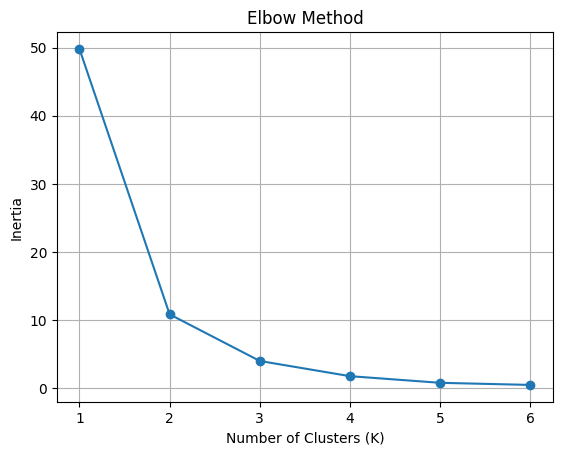

  Customer_ID  Annual_Income  Spending_Score  Cluster
0        C001          25000              78        1
1        C002          28000              72        1
2        C003          60000              45        0
3        C004          65000              40        0
4        C005          90000              20        2
5        C006          85000              25        2
6        C007          45000              65        1
7        C008          47000              68        1
8        C009         100000              15        2
9        C010          30000              80        1


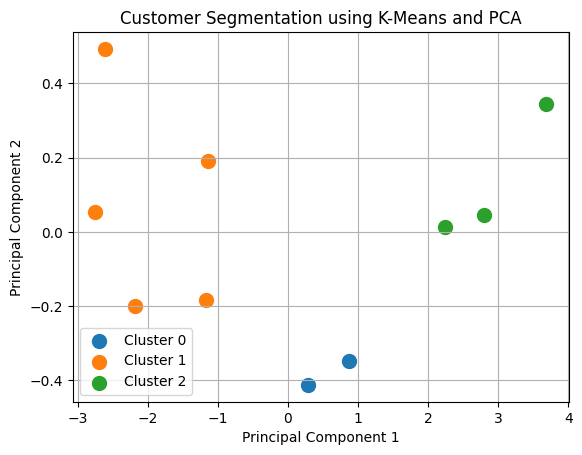

           Age  Annual_Income  Spending_Score  Visit_Frequency  \
Cluster                                                          
0        37.50       62500.00            42.5              4.5   
1        24.80       35000.00            72.6             10.4   
2        53.33       91666.67            20.0              2.0   

         Average_Purchase_Value  
Cluster                          
0                       3750.00  
1                       2020.00  
2                       6166.67  
[0.98087543 0.01532999]


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

data = {
    'Customer_ID': ['C001', 'C002', 'C003', 'C004', 'C005',
                    'C006', 'C007', 'C008', 'C009', 'C010'],
    'Age': [19, 22, 35, 40, 52, 48, 28, 31, 60, 24],
    'Annual_Income': [25000, 28000, 60000, 65000, 90000,
                      85000, 45000, 47000, 100000, 30000],
    'Spending_Score': [78, 72, 45, 40, 20, 25, 65, 68, 15, 80],
    'Visit_Frequency': [12, 10, 5, 4, 2, 3, 8, 9, 1, 13],
    'Average_Purchase_Value': [1500, 1800, 3500, 4000, 6000,
                               5500, 2500, 2700, 7000, 1600]
}

df = pd.DataFrame(data)

features = ['Age', 'Annual_Income', 'Spending_Score',
            'Visit_Frequency', 'Average_Purchase_Value']

X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

inertias = []

for k in range(1, 7):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_pca)
    inertias.append(kmeans.inertia_)

plt.plot(range(1, 7), inertias, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_pca)

df['PC1'] = X_pca[:, 0]
df['PC2'] = X_pca[:, 1]

print(df[['Customer_ID', 'Annual_Income',
          'Spending_Score', 'Cluster']])

for cluster in sorted(df['Cluster'].unique()):
    cluster_data = df[df['Cluster'] == cluster]
    plt.scatter(cluster_data['PC1'], cluster_data['PC2'],
                label=f'Cluster {cluster}', s=100)

plt.title('Customer Segmentation using K-Means and PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(True)
plt.show()

print(df.groupby('Cluster')[features].mean().round(2))
print(pca.explained_variance_ratio_)